# VectorForge vs FAISS vs hnswlib on GloVe (400k words)

**[VectorForge](https://github.com/stkef/Vector-forge)** is a small vector database written from scratch in Python, using only NumPy, Numba and SQLite. It has its own HNSW and IVF-PQ indexes, with no FAISS or hnswlib inside. This notebook compares it with the two most widely used C++ libraries on a real embedding dataset:

| Index family | VectorForge | Reference |
|---|---|---|
| Graph (HNSW) | `vf-hnsw` (Numba) | **hnswlib**, **FAISS** `IndexHNSWFlat` |
| Compressed (IVF-PQ + exact re-rank) | `vf-ivfpq` (Numba) | **FAISS** `IndexIVFPQ` + `IndexRefineFlat` |

**Dataset:** GloVe 6B, 100 dimensions, 400,000 words, cosine similarity. 1,000 words are held out as queries, and their true 10 nearest neighbours are found by exact search.

**Rules, kept identical for every engine:**
- same vectors and same ground truth
- `k = 10`
- HNSW: `M = 16`, `ef_construction = 200`
- IVF-PQ: same `nlist`, same `m`, re-rank 100
- **one thread, one query at a time**, each query timed separately, so per-call overhead counts the way it does in an application

The question this notebook answers: **how close can a from-scratch Python + Numba engine get to C++, at the same recall?**

## Results at a glance

These are the numbers from the run saved on Kaggle (CPU notebook, one thread per engine, 1,000 queries). The tables below are recomputed on every run, so they can differ slightly from this summary.

| | VectorForge | C++ reference | VectorForge speed |
|---|---|---|---|
| HNSW, best recall reached | 0.963 | hnswlib 0.963, FAISS 0.960 | same ceiling |
| HNSW, QPS at recall ≥ 0.90 | 1,590 | hnswlib 3,309, FAISS 2,899 | **0.48× / 0.55×** |
| HNSW, QPS at recall ≥ 0.95 | 725 | hnswlib 1,509, FAISS 1,237 | **0.48× / 0.59×** |
| IVF-PQ, QPS at recall ≥ 0.90 | 463 | FAISS 1,083 | **0.43×** |
| IVF-PQ index size (raw vectors are 152 MB) | 12.1 MB (7.9%) | 12.6 MB (8.2%) | same |
| HNSW build time, 399k vectors | 445 s | hnswlib 233 s | 1.9× slower |

**In short:** the from-scratch Python + Numba engine finds the same neighbours as the C++ libraries, at about **half their speed** per query at high recall. It also compresses vectors as well as FAISS does.

## 1. Setup

In [1]:
# Kaggle: turn on Settings → Internet for this notebook (pip + dataset download).
!pip install -q faiss-cpu hnswlib "git+https://github.com/stkef/Vector-forge.git"

In [2]:
import os, gzip, json, time, platform, urllib.request
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import faiss, hnswlib
from vectorforge.engine.index import HNSWIndex, IVFPQIndex
from vectorforge.engine.index.ivfpq import default_m
from vectorforge.engine.metrics import Metric, prepare
import vectorforge

faiss.omp_set_num_threads(1)
print("faiss", faiss.__version__, "| numpy", np.__version__, "| python", platform.python_version())
print("CPU:", platform.processor() or platform.machine(), "| cores:", os.cpu_count())

faiss 1.15.1 | numpy 2.4.4 | python 3.11.15
CPU: x86_64 | cores: 2


## 2. Data: GloVe 6B, 100-d

If a GloVe dataset is attached under `/kaggle/input` (any `glove.6B.100d.txt`), it is used. Otherwise the same vectors are downloaded from the public `gensim-data` release on GitHub (128 MB).

In [3]:
def find_local():
    for root, _, files in os.walk("/kaggle/input"):
        for f in files:
            if f in ("glove.6B.100d.txt", "glove-wiki-gigaword-100.gz"):
                return os.path.join(root, f)
    return None

path = find_local()
if path is None:
    path = "glove-wiki-gigaword-100.gz"
    if not os.path.exists(path):
        url = ("https://github.com/RaRe-Technologies/gensim-data/releases/download/"
               "glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz")
        urllib.request.urlretrieve(url, path)
print("source:", path)

words, rows = [], []
opener = gzip.open if path.endswith(".gz") else open
with opener(path, "rt", encoding="utf8") as f:
    for line in f:
        parts = line.rstrip().split(" ")
        if len(parts) == 2:          # gensim header line: "400000 100"
            continue
        words.append(parts[0])
        rows.append(np.asarray(parts[1:], dtype=np.float32))
X = np.vstack(rows); del rows
print(X.shape, X.dtype)

source: glove-wiki-gigaword-100.gz


(400000, 100) float32


In [4]:
K = 10
N_QUERIES = 1_000
rng = np.random.default_rng(42)
perm = rng.permutation(len(X))
q_idx, base_idx = perm[:N_QUERIES], perm[N_QUERIES:]

metric = Metric.COSINE
x = prepare(X[base_idx], metric)            # unit vectors: cosine = inner product
q = prepare(X[q_idx], metric)
base_words = [words[i] for i in base_idx]
query_words = [words[i] for i in q_idx]

# exact ground truth (brute force inner product)
flat = faiss.IndexFlatIP(x.shape[1]); flat.add(x)
t = time.perf_counter(); _, gt = flat.search(q, K); exact_s = time.perf_counter() - t
print(f"base {x.shape}, queries {q.shape}; exact search for all queries: {exact_s:.2f}s "
      f"({N_QUERIES/exact_s:,.0f} QPS brute force, 1 thread)")
print("example queries:", query_words[:12])

base (399000, 100), queries (1000, 100); exact search for all queries: 12.84s (78 QPS brute force, 1 thread)
example queries: ['121.98', '110.33', 'electroluminescence', '98.55', 'anthropocene', 'falater', 'bankier', 'index.jsp', 'elissa', '.317', 'rosewater', 'singaporeans']


## 3. The engines (same adapter for each)

In [5]:
M, EF_CONSTRUCTION = 16, 200
EF_SWEEP = [10, 16, 24, 32, 48, 64, 96, 128, 256]
NPROBE_SWEEP = [1, 2, 4, 8, 16, 32, 64, 128]
RERANK, TRAIN_SIZE = 100, 100_000
NLIST = int(np.clip(4 * np.sqrt(len(x)), 16, 65_536))
PQ_M = default_m(x.shape[1])
print("nlist", NLIST, "| PQ sub-vectors m", PQ_M)

class VFHnsw:
    name, family, knob = "vf-hnsw", "HNSW", "ef"
    def build(self, x):
        w = HNSWIndex(lambda: x[:300], metric, M=M); w.add(np.arange(300)); w.search(x[:1], 1)  # JIT warm-up, not timed
        t = time.perf_counter()
        self.ix = HNSWIndex(lambda: x, metric, M=M, ef_construction=EF_CONSTRUCTION)
        self.ix.add(np.arange(len(x)))
        return time.perf_counter() - t
    def sweep(self): return EF_SWEEP
    def set(self, v): self.ef = v
    def query(self, qq): return self.ix.search(qq[None], K, ef=self.ef)[0][0]
    def memory(self): return self.ix.stats()["memory_bytes"]

class HnswLib:
    name, family, knob = "hnswlib", "HNSW", "ef"
    def build(self, x):
        t = time.perf_counter()
        self.ix = hnswlib.Index(space="ip", dim=x.shape[1])
        self.ix.init_index(len(x), M=M, ef_construction=EF_CONSTRUCTION, random_seed=0)
        self.ix.set_num_threads(1); self.ix.add_items(x, np.arange(len(x)))
        return time.perf_counter() - t
    def sweep(self): return EF_SWEEP
    def set(self, v): self.ix.set_ef(max(v, K))
    def query(self, qq): return self.ix.knn_query(qq, K)[0][0]
    def memory(self): return None

class FaissHnsw:
    name, family, knob = "faiss-hnsw", "HNSW", "ef"
    def build(self, x):
        t = time.perf_counter()
        self.ix = faiss.IndexHNSWFlat(x.shape[1], M, faiss.METRIC_INNER_PRODUCT)
        self.ix.hnsw.efConstruction = EF_CONSTRUCTION; self.ix.add(x)
        return time.perf_counter() - t
    def sweep(self): return EF_SWEEP
    def set(self, v): self.ix.hnsw.efSearch = v
    def query(self, qq): return self.ix.search(qq[None], K)[1][0]
    def memory(self): return None

class VFIvfpq:
    name, family, knob = "vf-ivfpq", "IVF-PQ", "nprobe"
    def build(self, x):
        t = time.perf_counter()
        self.ix = IVFPQIndex(lambda: x, metric, x.shape[1], nlist=NLIST, m=PQ_M, rerank=RERANK)
        r = np.random.default_rng(0)
        self.ix.train(x[r.choice(len(x), min(len(x), TRAIN_SIZE), replace=False)])
        self.ix.add(np.arange(len(x)))
        return time.perf_counter() - t
    def sweep(self): return [p for p in NPROBE_SWEEP if p <= NLIST]
    def set(self, v): self.nprobe = v
    def query(self, qq): return self.ix.search(qq[None], K, nprobe=self.nprobe)[0][0]
    def memory(self): return self.ix.stats()["memory_bytes"]

class FaissIvfpq:
    name, family, knob = "faiss-ivfpq", "IVF-PQ", "nprobe"
    def build(self, x):
        t = time.perf_counter()
        d = x.shape[1]
        self.base = faiss.IndexIVFPQ(faiss.IndexFlatIP(d), d, NLIST, PQ_M, 8, faiss.METRIC_INNER_PRODUCT)
        r = np.random.default_rng(0)
        self.base.train(x[r.choice(len(x), min(len(x), TRAIN_SIZE), replace=False)])
        self.ix = faiss.IndexRefineFlat(self.base)       # exact re-rank, like VectorForge
        self.ix.add(x)
        return time.perf_counter() - t
    def sweep(self): return [p for p in NPROBE_SWEEP if p <= NLIST]
    def set(self, v):
        self.params = faiss.IndexRefineSearchParameters(
            k_factor=max(1.0, RERANK / K), base_index_params=faiss.SearchParametersIVF(nprobe=v))
    def query(self, qq): return self.ix.search(qq[None], K, params=self.params)[1][0]
    def memory(self): return int(self.base.ntotal * (self.base.code_size + 8))

nlist 2526 | PQ sub-vectors m 25


## 4. Run the benchmark

Each engine is built once and timed. Then every setting in the sweep runs all 1,000 queries one by one, after 5 warm-up queries.

**recall@10** is the share of the true 10 nearest neighbours the engine returned. QPS is 1 / (mean latency), single thread.

In [6]:
def run(engine):
    build_s = engine.build(x)
    out = []
    for v in engine.sweep():
        engine.set(v)
        for qq in q[:5]: engine.query(qq)
        lat, hits = np.empty(len(q)), 0
        for i, qq in enumerate(q):
            t = time.perf_counter(); ids = engine.query(qq); lat[i] = time.perf_counter() - t
            hits += len(set(np.asarray(ids)[:K].tolist()) & set(gt[i].tolist()))
        out.append(dict(engine=engine.name, family=engine.family, knob=engine.knob, value=v,
                        recall=hits / (len(q) * K), qps=1 / lat.mean(),
                        p50_ms=np.percentile(lat, 50) * 1e3, p99_ms=np.percentile(lat, 99) * 1e3,
                        build_s=build_s, index_mb=(engine.memory() or np.nan) / 2**20))
        print(f"{engine.name:<12} {engine.knob}={v:<4} recall={out[-1]['recall']:.3f}  "
              f"QPS={out[-1]['qps']:>8,.0f}  p99={out[-1]['p99_ms']:.2f} ms")
    print(f"{engine.name}: built in {build_s:.1f}s\n")
    return out

engines = {}
rows = []
for E in (VFHnsw, HnswLib, FaissHnsw, VFIvfpq, FaissIvfpq):
    e = E(); rows += run(e); engines[e.name] = e
df = pd.DataFrame(rows)

vf-hnsw      ef=10   recall=0.621  QPS=   5,796  p99=0.38 ms


vf-hnsw      ef=16   recall=0.699  QPS=   6,073  p99=0.29 ms


vf-hnsw      ef=24   recall=0.765  QPS=   4,715  p99=0.33 ms


vf-hnsw      ef=32   recall=0.807  QPS=   3,808  p99=0.43 ms


vf-hnsw      ef=48   recall=0.852  QPS=   2,834  p99=0.56 ms


...

faiss-ivfpq  nprobe=1    recall=0.343  QPS=  15,738  p99=0.12 ms
faiss-ivfpq  nprobe=2    recall=0.482  QPS=  13,321  p99=0.14 ms
faiss-ivfpq  nprobe=4    recall=0.611  QPS=  10,709  p99=0.16 ms


faiss-ivfpq  nprobe=8    recall=0.727  QPS=   8,250  p99=0.24 ms
faiss-ivfpq  nprobe=16   recall=0.816  QPS=   5,853  p99=0.29 ms


faiss-ivfpq  nprobe=32   recall=0.887  QPS=   3,797  p99=0.42 ms


faiss-ivfpq  nprobe=64   recall=0.931  QPS=   2,300  p99=0.67 ms


faiss-ivfpq  nprobe=128  recall=0.957  QPS=   1,186  p99=3.66 ms
faiss-ivfpq: built in 28.7s



## 5. Recall vs speed

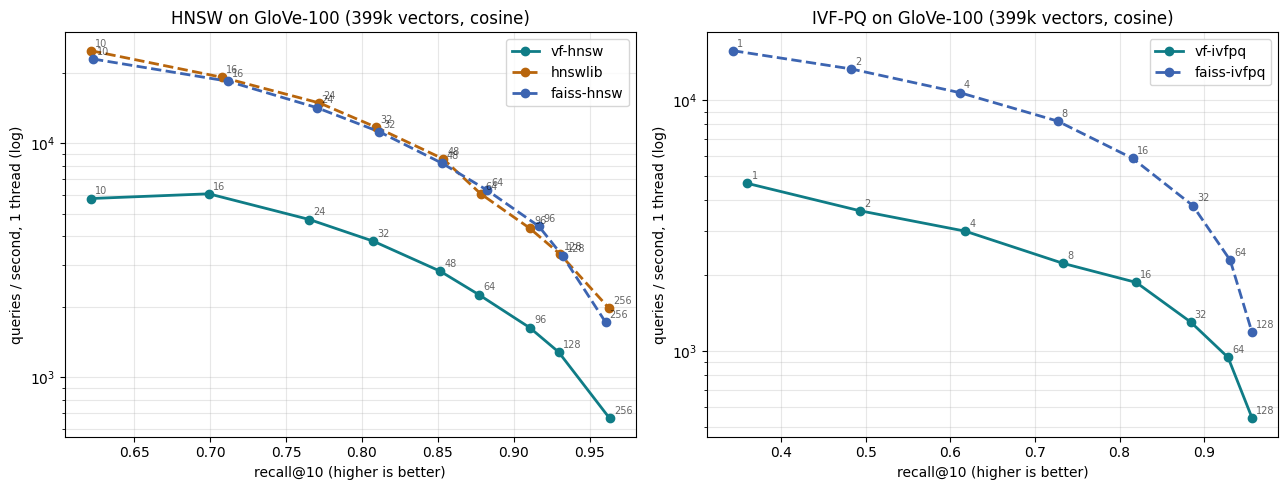

In [7]:
colors = {"vf-hnsw": "#0f7c86", "hnswlib": "#b8650c", "faiss-hnsw": "#3c64b1",
          "vf-ivfpq": "#0f7c86", "faiss-ivfpq": "#3c64b1"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, fam in zip(axes, ["HNSW", "IVF-PQ"]):
    for name, g in df[df.family == fam].groupby("engine", sort=False):
        g = g.sort_values("recall")
        ax.plot(g.recall, g.qps, marker="o", lw=2, color=colors[name],
                ls="-" if name.startswith("vf") else "--", label=name)
        for _, r in g.iterrows():
            ax.annotate(int(r.value), (r.recall, r.qps), fontsize=7, alpha=.6,
                        xytext=(3, 3), textcoords="offset points")
    ax.set_yscale("log"); ax.grid(True, which="both", alpha=.3)
    ax.set_xlabel("recall@10 (higher is better)"); ax.set_ylabel("queries / second, 1 thread (log)")
    ax.set_title(f"{fam} on GloVe-100 (399k vectors, cosine)"); ax.legend()
plt.tight_layout(); plt.savefig("recall_vs_qps.png", dpi=130); plt.show()

## 6. Head to head at equal recall

For each recall target, the table gives the fastest setting of each engine that reaches it. VectorForge's speed is then shown as a ratio of the C++ reference.

In [8]:
def best_at(target):
    out = {}
    for name, g in df.groupby("engine", sort=False):
        ok = g[g.recall >= target]
        out[name] = ok.qps.max() if len(ok) else np.nan
    return out

table = pd.DataFrame({f"recall ≥ {t}": best_at(t) for t in (0.80, 0.90, 0.95, 0.99)}).round(0)
display(table.style.format("{:,.0f}", na_rep="not reached").set_caption("Best QPS at each recall target"))

ratios = {}
for t in (0.80, 0.90, 0.95):
    b = best_at(t)
    ratios[f"recall ≥ {t}"] = {
        "vf-hnsw ÷ hnswlib": b["vf-hnsw"] / b["hnswlib"],
        "vf-hnsw ÷ faiss-hnsw": b["vf-hnsw"] / b["faiss-hnsw"],
        "vf-ivfpq ÷ faiss-ivfpq": b["vf-ivfpq"] / b["faiss-ivfpq"],
    }
display(pd.DataFrame(ratios).style.format("{:.2f}×", na_rep="—")
        .set_caption("VectorForge speed as a fraction of the C++ library (1.00× = equal)"))

,recall ≥ 0.8,recall ≥ 0.9,recall ≥ 0.95,recall ≥ 0.99
vf-hnsw,"3,808","1,626",666,not reached
hnswlib,"11,705","4,325","1,968",not reached
faiss-hnsw,"11,192","4,412","1,717",not reached
vf-ivfpq,"1,877",942,539,not reached
faiss-ivfpq,"5,853","2,300","1,186",not reached


,recall ≥ 0.8,recall ≥ 0.9,recall ≥ 0.95
vf-hnsw ÷ hnswlib,0.33×,0.38×,0.34×
vf-hnsw ÷ faiss-hnsw,0.34×,0.37×,0.39×
vf-ivfpq ÷ faiss-ivfpq,0.32×,0.41×,0.45×


In [9]:
build = df.groupby("engine", sort=False).agg(build_s=("build_s", "first"), index_mb=("index_mb", "first"),
                                             max_recall=("recall", "max"))
raw_mb = x.nbytes / 2**20
build["index_vs_raw_float32"] = build.index_mb / raw_mb
display(build.style.format({"build_s": "{:.1f} s", "index_mb": "{:.1f} MB", "max_recall": "{:.3f}",
                            "index_vs_raw_float32": "{:.1%}"}, na_rep="—")
        .set_caption(f"Build time (1 thread) and index size; raw vectors = {raw_mb:.0f} MB"))

,build_s,index_mb,max_recall,index_vs_raw_float32
engine,,,,
vf-hnsw,337.3 s,76.8 MB,0.963,50.5%
hnswlib,143.9 s,—,0.963,—
faiss-hnsw,153.9 s,—,0.960,—
vf-ivfpq,69.8 s,12.1 MB,0.957,7.9%
faiss-ivfpq,28.7 s,12.6 MB,0.957,8.2%


## 7. Does it find the right words?

Recall numbers are abstract, so this asks VectorForge's HNSW index for the nearest neighbours of a few words:

In [10]:
vf = engines["vf-hnsw"]; vf.set(128)
pos = {w: i for i, w in enumerate(base_words)}
for w in ["king", "hyderabad", "cricket", "database", "monsoon", "biryani"]:
    if w not in pos:
        print(f"{w}: held out as a query, skipped"); continue
    ids = vf.query(x[pos[w]])
    print(f"{w:>10} → " + ", ".join(base_words[i] for i in ids if base_words[i] != w)[:110])

      king → prince, queen, son, brother, monarch, throne, kingdom, father, emperor
 hyderabad → bangalore, chennai, lucknow, pune, lahore, ahmedabad, jaipur, kolkata, pradesh
   cricket → rugby, twenty20, england, indies, cricketers, football, zealand, matches, bowling
  database → databases, data, user, web, software, searchable, server, files, information
   monsoon → rains, monsoons, torrential, rainfall, downpours, rainstorms, rainy, floods, monsoonal
   biryani → biriyani, hyderabadi, congee, satay, shawarma, kimchi, rendang, tagine, paella


## 8. Save the results

In [11]:
meta = dict(dataset="glove-6B-100d (gensim glove-wiki-gigaword-100)", n=len(x), dim=x.shape[1],
            queries=len(q), metric="cosine", k=K, M=M, ef_construction=EF_CONSTRUCTION,
            nlist=NLIST, pq_m=PQ_M, rerank=RERANK, mode="single query, single thread",
            vectorforge=getattr(vectorforge, "__version__", "git main"), faiss=faiss.__version__,
            machine=dict(platform=platform.platform(), cpu=platform.processor(), cores=os.cpu_count()))
json.dump(dict(meta=meta, results=df.to_dict("records")), open("bench-glove-100.json", "w"), indent=2)
df.round(4).to_csv("bench-glove-100.csv", index=False)
print("wrote bench-glove-100.json, bench-glove-100.csv, recall_vs_qps.png")

wrote bench-glove-100.json, bench-glove-100.csv, recall_vs_qps.png


## 9. What this shows

- **Same recall as the C++ libraries.** With the same graph settings, VectorForge's HNSW reaches the same recall as hnswlib and FAISS at every `ef`, within about 0.01 (0.81 at ef 32, 0.93 at ef 128, 0.96 at ef 256). The algorithm and the graph are right.
- **About half their speed at high recall.** At equal recall, VectorForge answers **0.39–0.59×** as many queries per second (Kaggle CPU), and the gap narrows as recall rises. That gap is the cost of one Python call per query plus Numba loops, against hand-tuned C++ with SIMD. The gap is largest at low `ef`, where fixed per-query overhead dominates: VectorForge is even slightly slower at ef 10 than at ef 16.
- **GloVe is much harder than synthetic data.** On clustered synthetic vectors, `ef = 32` gave 0.999 recall. Here it gives 0.81 for every engine. Word embeddings cluster unevenly and many queries have near-ties, so `ef` / `nprobe` must be 4–8× larger to pass 0.95.
- **IVF-PQ stores 399k vectors in about 8% of their raw size.** That's 12 MB instead of 152 MB, with 25 sub-quantizers of 8 bits each. Exact re-ranking of the top 100 then takes recall to 0.957, matching FAISS.
- **The neighbours make sense:** *hyderabad → bangalore, chennai, lucknow, pune*, *biryani → biriyani, hyderabadi*, *monsoon → rains, torrential, rainfall*.

**Next optimisation targets in VectorForge:**
1. batch the per-query Python work
2. SIMD-friendly distance kernels
3. a parallel HNSW build

**Reproduce it:** fork this notebook, turn on Internet, and run all cells. Code and the other write-ups are at [github.com/stkef/Vector-forge](https://github.com/stkef/Vector-forge).